# XGBoost Validation Baseline

Boosting builds trees sequentially, with later trees correcting patterns left by earlier trees. Unlike a Random Forest, which averages independently built trees, boosted trees form an additive sequence. This can represent nonlinear relationships and interactions in tabular data, but performance must be measured rather than assumed.

This is an untuned Phase 9 baseline. It uses the 42 ordered features from `feature_schema.json`, fits only on TRAIN, and evaluates on VALIDATION. Tree split decisions do not require StandardScaler, so no scaling is applied. Tuning is deferred to Phase 10. The test set is not loaded or evaluated, and no model is saved.

In [4]:
from pathlib import Path
import importlib
import sys
import pandas as pd
import matplotlib.pyplot as plt

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidate_roots if (p / 'ml/src/train_xgboost.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate ml/src/train_xgboost.py')
sys.path.insert(0, str(PROJECT_ROOT))
import ml.src.train_xgboost as xgboost_module
importlib.reload(xgboost_module)
report, artifacts = xgboost_module.run_phase9()
print('Evaluation split:', report['evaluation_split'])
print('Train / validation rows / features:', report['train_rows'], report['validation_rows'], report['feature_count'])
print('Target / horizon:', report['target'], report['forecast_horizon_minutes'], 'minutes')
print('Resolved XGBoost parameters:')
print(report['resolved_xgboost_parameters'])
print('Scaling:', report['scaling_applied'], '| tuning:', report['hyperparameter_tuning_performed'], '| early stopping:', report['early_stopping_used'])
print('Test set was not loaded or evaluated in Phase 9.')

Evaluation split: validation
Train / validation rows / features: 13108 2809 42
Target / horizon: target_appliances_next 10 minutes
Resolved XGBoost parameters:
{'n_estimators': 100, 'learning_rate': 0.3, 'max_depth': 6, 'min_child_weight': 1, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_alpha': 0.0, 'reg_lambda': 1.0, 'objective': 'reg:squarederror', 'random_state': 42, 'n_jobs': 1, 'tree_method': 'hist', 'verbosity': 0, 'enable_categorical': True}
Scaling: False | tuning: False | early stopping: False
Test set was not loaded or evaluated in Phase 9.


## Validation Comparison

Persistence, Linear Regression, and Random Forest metrics are reused from the existing validation-only JSON files. XGBoost is fitted on training data and scored on validation data. RMSE is the primary comparison metric; this is a current validation ranking, not final model selection.

,MAE,RMSE,R²
Persistence Baseline,25.920256,65.794972,0.465273
Linear Regression,27.025294,59.346237,0.564956
Random Forest,53.004521,100.818362,-0.255527
XGBoost,54.392578,90.577337,-0.013412


Current best validation model by RMSE: Linear Regression
XGBoost RMSE improvement vs persistence (%): -37.666047177350556
XGBoost RMSE improvement vs Linear Regression (%): -52.62523922805317
XGBoost RMSE improvement vs Random Forest (%): 10.1578968776155
Actual vs Predicted period: first 7 contiguous validation days, 2016-04-18 17:40:00 through 2016-04-25 17:30:00 (1008 observations)


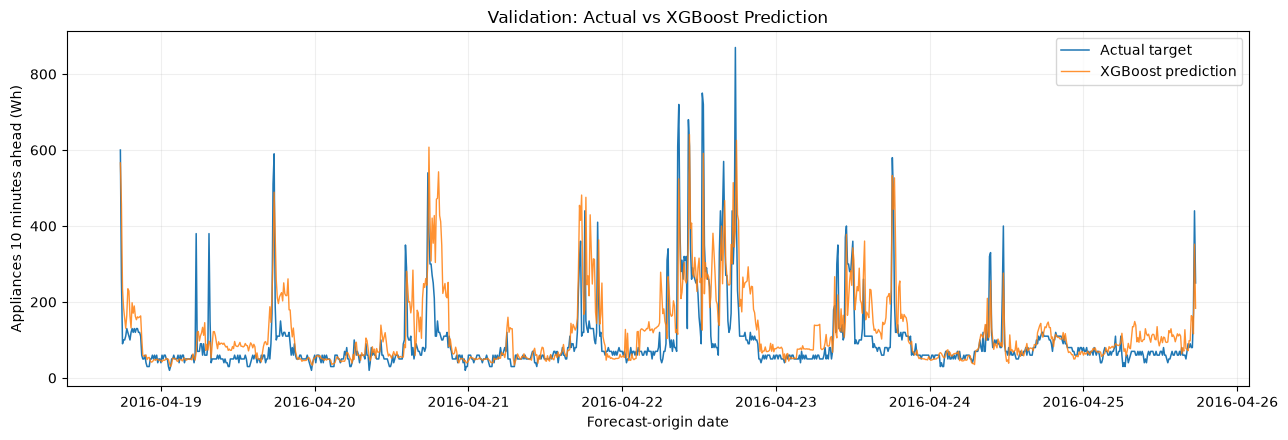

In [5]:
comparison = pd.DataFrame.from_dict(report['validation_model_comparison'], orient='index')
comparison = comparison.rename(columns={'mae': 'MAE', 'rmse': 'RMSE', 'r2': 'R²'})
display(comparison)
print('Current best validation model by RMSE:', report['current_best_validation_model_by_rmse'])
print('XGBoost RMSE improvement vs persistence (%):', report['xgboost_rmse_improvement_vs_persistence_percent'])
print('XGBoost RMSE improvement vs Linear Regression (%):', report['xgboost_rmse_improvement_vs_linear_regression_percent'])
print('XGBoost RMSE improvement vs Random Forest (%):', report['xgboost_rmse_improvement_vs_random_forest_percent'])
validation_dates = artifacts['validation_dates']
window_mask = validation_dates < validation_dates.iloc[0] + pd.Timedelta(days=7)
window_dates = validation_dates.loc[window_mask]
actual_window = artifacts['actual'].loc[window_mask]
prediction_window = artifacts['predictions'].loc[window_mask]
print('Actual vs Predicted period: first 7 contiguous validation days,', window_dates.iloc[0], 'through', window_dates.iloc[-1], f'({len(window_dates)} observations)')
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(window_dates, actual_window, label='Actual target', linewidth=1.1)
ax.plot(window_dates, prediction_window, label='XGBoost prediction', linewidth=1.0, alpha=0.85)
ax.set(title='Validation: Actual vs XGBoost Prediction', xlabel='Forecast-origin date', ylabel='Appliances 10 minutes ahead (Wh)')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Residuals and Limitations

Residuals are actual validation target minus XGBoost prediction. These summaries/plots are validation-only diagnostics. No observations are removed and no settings are changed based on these errors. The configuration is intentionally untuned; Phase 10 will handle controlled tuning. Results from one chronological collection do not establish generalization or causation.

XGBoost validation residual summary (actual - predicted):


count    2809.000000
mean      -33.896608
std        84.010635
min      -515.131714
25%       -58.395599
50%       -17.626251
75%         2.625526
max       624.005539
dtype: float64

Mean validation residual: -33.896608291380176
Sample standard deviation of residuals: 84.01063481384091


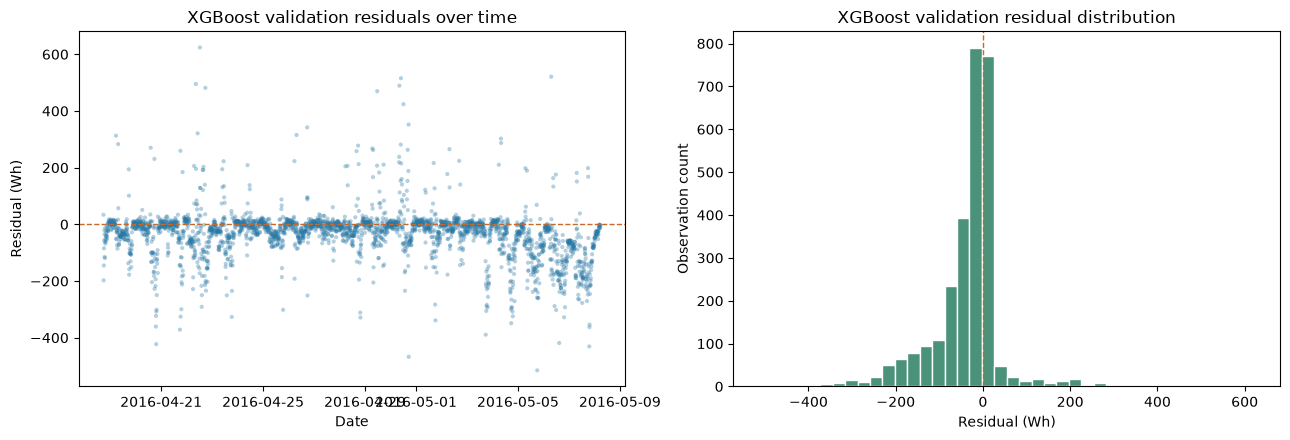

In [6]:
residuals = artifacts['residuals']
print('XGBoost validation residual summary (actual - predicted):')
display(residuals.describe())
print('Mean validation residual:', float(residuals.mean()))
print('Sample standard deviation of residuals:', float(residuals.std(ddof=1)))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(validation_dates, residuals, s=9, alpha=0.35, color='#2878A5', edgecolors='none')
axes[0].axhline(0, color='#C46A2D', linestyle='--', linewidth=1)
axes[0].set(title='XGBoost validation residuals over time', xlabel='Date', ylabel='Residual (Wh)')
axes[1].hist(residuals, bins=40, color='#4B927A', edgecolor='white')
axes[1].axvline(0, color='#C46A2D', linestyle='--', linewidth=1)
axes[1].set(title='XGBoost validation residual distribution', xlabel='Residual (Wh)', ylabel='Observation count')
fig.tight_layout()
plt.show()
assert report['test_set_accessed'] is False
assert report['scaling_applied'] is False
assert report['hyperparameter_tuning_performed'] is False
assert report['early_stopping_used'] is False
assert report['model_artifact_saved'] is False